# EO4FLOOD river discharge and satellite proxies

EO4FLOOD is an ESA-funded project estimating river discharge from satellite Earth observation across
basins including the Po, Ebro, Danube and Rhine. Satellites measure quantities related to discharge—
river width, surface reflectance and water level—which are converted into discharge estimates.
The estimates and their proxy observations tell related but different parts of the hydrological story.

This Ebro demonstration reads basin-wide Parquet assets identified by the STAC items. It compares
four gauged discharge estimates and an ungauged-location product, then examines Sentinel-2 width,
surface reflectance and satellite altimetry. The selected examples do not all occupy the same site,
so their panels illustrate the products rather than form a co-located validation experiment.

## Discharge estimates at a gauge

The four products estimate discharge from different information: multi-mission merged observations
(`mmMerged`), multi-mission water level (`mmWLBased`), surface reflectance (`ReflectanceBased`), and
river width (`WidthBased`). Each basin-wide file contains multiple stations identified by `gauge_name`.

`Q` is discharge in m³/s and `Q_unc` is the delivered uncertainty in the same units. Sampling depends
on the product and station; gaps denote unavailable estimates rather than zero discharge. The
example is station 6226400_GRDC.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DISCHARGE_URLS = {'mmMerged': 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/River_Discharge_series/Ebro_River_Discharge_mmMerged.parquet', 'mmWLBased': 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/River_Discharge_series/Ebro_River_Discharge_mmWLBased.parquet', 'ReflectanceBased': 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/River_Discharge_series/Ebro_River_Discharge_ReflectanceBased.parquet', 'WidthBased': 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/River_Discharge_series/Ebro_River_Discharge_WidthBased.parquet'}
BASIN = "Ebro"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

GAUGE = b"6226400_GRDC"
PRODUCTS = ["mmMerged", "mmWLBased", "ReflectanceBased", "WidthBased"]
discharge = {}
for product in PRODUCTS:
    url = DISCHARGE_URLS[product]
    table = pd.read_parquet(url)
    discharge[product] = table.loc[table.gauge_name == GAUGE].sort_values("time")
merged = discharge["mmMerged"]
merged.head()

,time,Q,Q_unc,basin,gauge_name,gauge_lat,gauge_lon,title,creation_time,institution,contact,pdate,temporal interval,version,Conventions,DOI,Acknowledgements
0,2016-01-01,NaN,NaN,b'Ebro',b'6226400_GRDC',41.658569,-0.88106,ESA EO4FLOOD project river discharge (multi-mi...,2026-07-31 10:52:55,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-07-31,01-Jan-2016 to 31-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
1,2016-01-02,261.352661,27.522137,b'Ebro',b'6226400_GRDC',41.658569,-0.88106,ESA EO4FLOOD project river discharge (multi-mi...,2026-07-31 10:52:55,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-07-31,01-Jan-2016 to 31-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
2,2016-01-03,NaN,NaN,b'Ebro',b'6226400_GRDC',41.658569,-0.88106,ESA EO4FLOOD project river discharge (multi-mi...,2026-07-31 10:52:55,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-07-31,01-Jan-2016 to 31-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
3,2016-01-04,NaN,NaN,b'Ebro',b'6226400_GRDC',41.658569,-0.88106,ESA EO4FLOOD project river discharge (multi-mi...,2026-07-31 10:52:55,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-07-31,01-Jan-2016 to 31-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
4,2016-01-05,262.835815,27.201572,b'Ebro',b'6226400_GRDC',41.658569,-0.88106,ESA EO4FLOOD project river discharge (multi-mi...,2026-07-31 10:52:55,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-07-31,01-Jan-2016 to 31-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference


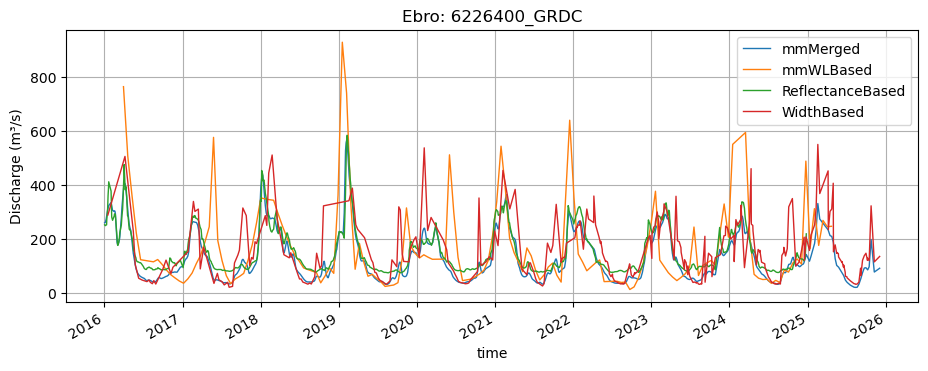

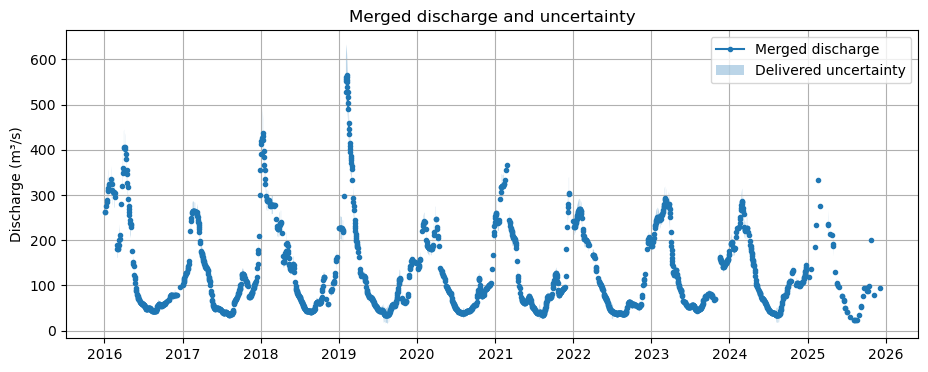

In [3]:
fig, ax = plt.subplots()
for product, table in discharge.items():
    table.set_index("time").Q.dropna().plot(ax=ax, label=product, linewidth=1)
ax.set(ylabel="Discharge (m³/s)", title=f"{BASIN}: {GAUGE.decode()}")
ax.legend()
plt.show()
fig, ax = plt.subplots()
ax.plot(merged.time, merged.Q, ".-", label="Merged discharge")
ax.fill_between(merged.time, merged.Q - merged.Q_unc, merged.Q + merged.Q_unc,
                alpha=0.3, label="Delivered uncertainty")
ax.set(ylabel="Discharge (m³/s)", title="Merged discharge and uncertainty")
ax.legend()
plt.show()

## Multi-mission discharge at an ungauged location

The ungauged product provides estimates at locations without a corresponding in-situ gauge series.
`q` is discharge, and `q_u_lower` and `q_u_upper` are the delivered lower and upper uncertainty
bounds, all in m³/s. These bounds need not be symmetric around the estimate. The example is the
Cinca site `ebro_cinca_47191`; its observation timestamps are carried by `date`.

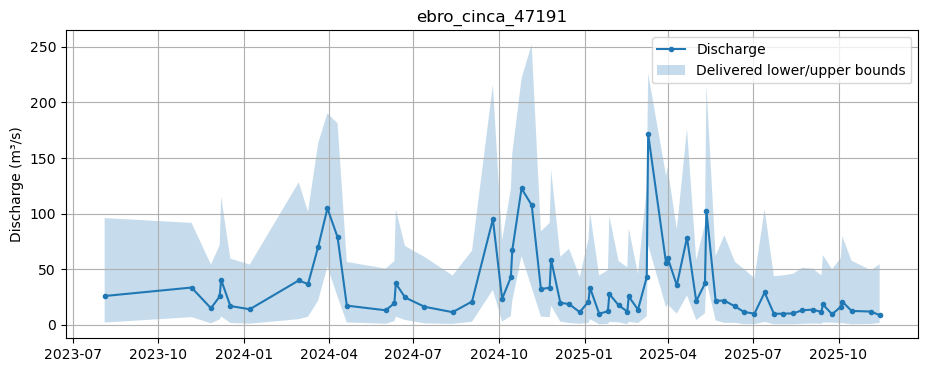

In [4]:
UNGAUGED_SITE = "ebro_cinca_47191"
url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/River_Discharge_series/Ebro_River_Discharge_Ungauged.parquet'
table = pd.read_parquet(url)
ungauged = table.loc[table.name == UNGAUGED_SITE].sort_values("date")
time = pd.to_datetime(ungauged.date)
fig, ax = plt.subplots()
ax.plot(time, ungauged.q, ".-", label="Discharge")
ax.fill_between(time, ungauged.q_u_lower, ungauged.q_u_upper, alpha=0.25, label="Delivered lower/upper bounds")
ax.set(ylabel="Discharge (m³/s)", title=UNGAUGED_SITE)
ax.legend()
plt.show()

## River width from Sentinel-2

River width is one of the satellite-observed proxies related to discharge. The width product
combines multiple stations and Landsat or Sentinel-2 observations; this example isolates Sentinel-2
at 6226400_GRDC. `w` is width in metres. The delivery provides no uncertainty column for this product.

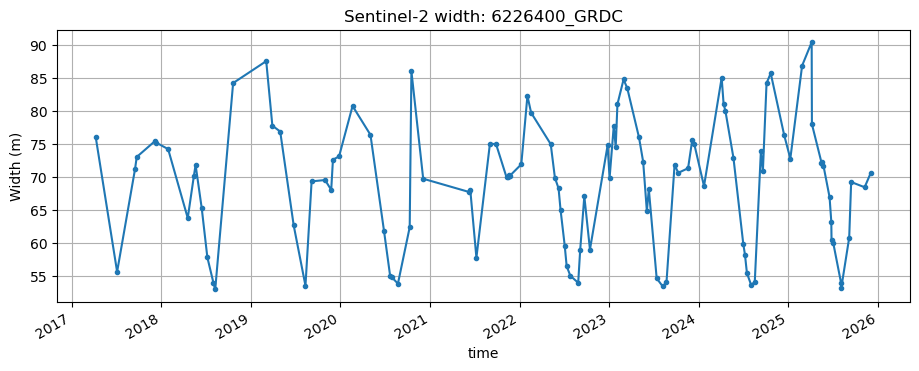

In [5]:
MISSION = b"Sentinel-2"
url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/width_series/Ebro_width_timeseries.parquet'
table = pd.read_parquet(url)
width = table.loc[(table.gauge_name == GAUGE) & (table.satellite == MISSION)].sort_values("time")
width.set_index("time").w.plot(marker=".", ylabel="Width (m)", title=f"{MISSION.decode()} width: {GAUGE.decode()}")
plt.show()

## Surface reflectance index

The surface-reflectance product contains separate MODIS Terra (`MOD`), MODIS Aqua (`MYD`) and
Sentinel-2 (`S2`) index series and a merged multi-mission series. Site coordinates locate each
sampling location. These dimensionless indices are proxies related to discharge, not discharge
measurements or raw reflectance constrained to the interval zero to one.

The Sentinel-2 series at site zero is shown with its delivered lower and upper uncertainty bounds.
Mission-dependent sampling and missing retrievals produce gaps in the series.

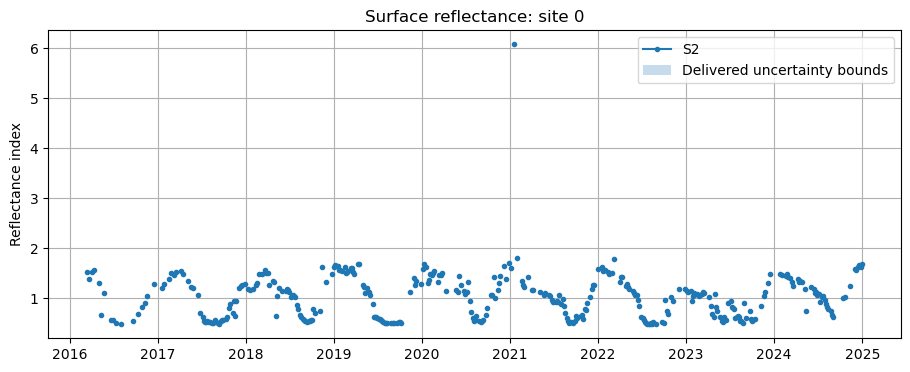

In [6]:
SITE = 0
REFLECTANCE_MISSION = "S2"
url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/surface_reflectance_index_series/Ebro_surface_reflectance_index.parquet'
table = pd.read_parquet(url)
reflectance = table.loc[table.site == SITE].sort_values("time")
variable = f"surface_reflectance_index_{REFLECTANCE_MISSION}"
fig, ax = plt.subplots()
ax.plot(reflectance.time, reflectance[variable], ".-", label=REFLECTANCE_MISSION)
ax.fill_between(reflectance.time, reflectance[f"{variable}_uncertainty_min"],
                reflectance[f"{variable}_uncertainty_max"], alpha=0.25, label="Delivered uncertainty bounds")
ax.set(ylabel="Reflectance index", title=f"Surface reflectance: site {SITE}")
ax.legend()
plt.show()

## Satellite altimetry at a virtual station

Altimetry provides a water-level proxy. DAHITI combines observations from satellite missions at
virtual stations identified by `dahiti_id`. `wse` is water surface elevation in metres and `wse_u`
is its uncertainty. The example station is 18470; the error bars retain the uncertainty of each observation.

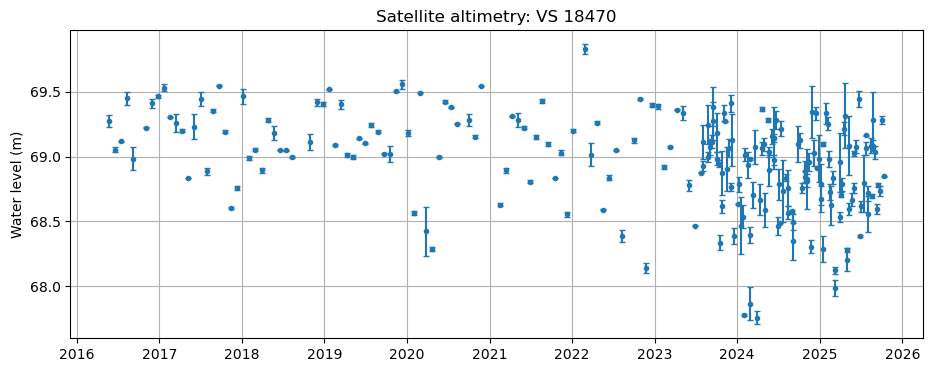

In [7]:
ALTIMETRY_STATION = "18470"
url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/water_level_series/Ebro_water_level_at_VS.parquet'
table = pd.read_parquet(url)
altimetry = table.loc[table.dahiti_id == ALTIMETRY_STATION].sort_values("datetime")
time = pd.to_datetime(altimetry.datetime)
fig, ax = plt.subplots()
ax.errorbar(time, altimetry.wse, yerr=altimetry.wse_u, fmt=".", capsize=2)
ax.set(ylabel="Water level (m)", title=f"Satellite altimetry: VS {ALTIMETRY_STATION}")
plt.show()

## Spatial context

The map locates the four examples. Discharge and width share the selected gauge location, while
the reflectance, ungauged-discharge and altimetry sites are separate. Their coordinates are part
of the product metadata and help distinguish product differences from location differences.

,name,lon,lat
0,Discharge / width,-0.881060,41.658569
1,Reflectance,0.192165,42.289719
2,Altimetry,0.367100,41.306000
3,Ungauged discharge,0.335700,41.540100


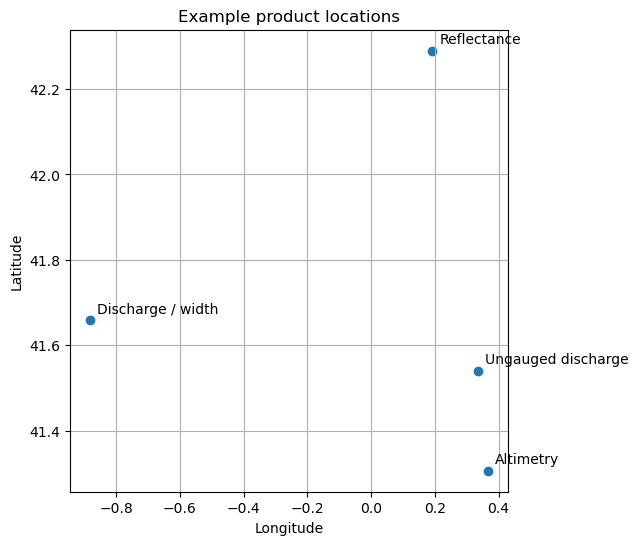

In [8]:
locations = pd.DataFrame({
    "name": ["Discharge / width", "Reflectance", "Altimetry", "Ungauged discharge"],
    "lon": [merged.gauge_lon.iloc[0], reflectance.siteX.iloc[0], altimetry.longitude.iloc[0], ungauged.lon.iloc[0]],
    "lat": [merged.gauge_lat.iloc[0], reflectance.siteY.iloc[0], altimetry.latitude.iloc[0], ungauged.lat.iloc[0]]
})
display(locations)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(locations.lon, locations.lat)
for row in locations.itertuples():
    ax.annotate(row.name, (row.lon, row.lat), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Example product locations")
ax.set_aspect(1 / np.cos(np.deg2rad(locations.lat.mean())))
plt.show()